# Steganografia obraz-w-obrazie: algorytm **KSX-LSB**

## 1. Wprowadzenie

W tym notebooku ukrywamy **obraz tajny** (*secret*) wewnątrz **obrazu nośnika** (*cover*). Wynik nazywamy **stego-obrazem** (*stego*). Ma on wyglądać jak nośnik, a jednocześnie pozwalać odzyskać obraz tajny.

### 1.1 Podstawa: najmłodszy bit (LSB)
Każdy piksel obrazu RGB to trzy liczby (kanały R, G, B) z zakresu 0–255, czyli po 8 bitów każda. Bity różnią się ważnością:

- **najstarsze bity (MSB)** mocno wpływają na wartość (zmiana najstarszego bitu to zmiana o 128),
- **najmłodsze bity (LSB)** wpływają na nią minimalnie (zmiana najmłodszego bitu to zmiana o 1).

Ludzkie oko nie zauważy zmiany jasności o 1–3 poziomy z 256, więc najmłodsze bity możemy **nadpisać cudzymi danymi**. Przykład dla `k = 2` (nadpisujemy 2 najmłodsze bity):

```
wartość kanału nośnika :  200 = 1100 1000
porcja do ukrycia      :    2 =        10
nowa wartość kanału    :  202 = 1100 1010     (zmiana tylko o 2)
```

Przy `k` nadpisanych bitach kanał zmienia się o najwyżej `2^k − 1` (dla `k = 2` o 3 poziomy).

### 1.2 Ile da się ukryć? Pomysł: rozdzielczość za głębię kolorów
Jeśli w każdym z `H·W·3` kanałów nośnika użyjemy `k` bitów, to nośnik pomieści `H·W·3·k` bitów. Pełny obraz RGB w 8 bitach na kanał wymaga `8·3` bitów na piksel, więc obraz tajny **nie zmieści się** w nośniku tego samego rozmiaru (potrzebowalibyśmy `k = 8`, co zniszczyłoby nośnik).

Mamy dwie drogi:
1. zachować rozdzielczość sekretu, ale obciąć każdy kanał do `k` bitów (powstaje **posteryzacja** – mało poziomów jasności),
2. **zmniejszyć rozdzielczość sekretu** i zachować w pełni 8 bitów na kanał (kolory są wierne, ale obraz jest mniejszy).

KSX-LSB wybiera drogę 2. Obraz tajny jest zmniejszany dokładnie tyle, ile trzeba, by się zmieścił, i dzięki temu **odzysk jest bezstratny** (w rozmiarze, w którym sekret ukryto), a proporcje obrazu zostają zachowane.

### 1.3 Po co klucz, permutacja i XOR?
Gdyby porcje bitów wpisywać po kolei, najmłodsze bity nośnika miałyby uporządkowaną strukturę (nagłówek, potem dane sekretu), a każdy, kto zna metodę, odczytałby sekret. Dlatego:

- **Permutacja** – porcje trafiają na pseudolosowe pozycje wyznaczone z klucza `key`. Bez klucza nie wiadomo, gdzie jest który kawałek.
- **XOR z maską** – każda porcja jest „odwracana" losową maską z klucza (XOR jest odwracalny: `(a XOR m) XOR m = a`). Dzięki temu najmłodsze bity wyglądają jak szum o równomiernym rozkładzie, także w miejscach, gdzie sekret ma jednolite obszary (same zera lub jedynki).

### 1.4 Algorytm KSX-LSB (*Key-Scrambled XOR LSB*)
Parametry: `key` – klucz (liczba całkowita), `k` – liczba najmłodszych bitów nośnika używanych w każdym kanale.

**Osadzanie**
1. Oblicz pojemność nośnika (`H·W·3·k` bitów) i zmniejsz obraz tajny (z zachowaniem proporcji) tak, aby się zmieścił. Jeśli jest dość mały, zostaje bez zmian.
2. Zbuduj strumień bitów: **nagłówek** (wysokość i szerokość sekretu, 2 × 16 bitów) + wszystkie 8 bitów każdego kanału sekretu.
3. Pokrój strumień na **porcje po `k` bitów** (jedna porcja = jeden kanał nośnika). Niewykorzystane porcje uzupełnij zerami.
4. **Permutacja:** przenieś porcje na pseudolosowe pozycje (wyznaczone z `key`).
5. **XOR:** zrób XOR każdej porcji z pseudolosową maską (też z `key`).
6. Wpisz porcje w `k` najmłodszych bitów kanałów nośnika.

**Wyodrębnianie** (tylko `stego`, `key`, `k`): odczytaj `k` najmłodszych bitów każdego kanału → XOR z tą samą maską → permutacja odwrotna → złóż bity → odczytaj nagłówek (rozmiar sekretu) → odtwórz obraz.

### 1.5 Własności i ograniczenia
- Zniekształcenie nośnika zależy tylko od `k`.
- Mały nośnik = mały sekret (np. nośnik 200×200 przy `k = 2` pomieści sekret ok. 100×100).
- Metoda **nie jest odporna** na kompresję stratną (JPEG), skalowanie ani przycinanie, bo każda taka operacja zmienia najmłodsze bity. Stego-obraz zapisuj w formacie bezstratnym (PNG).
- To nie jest bezpieczna kryptografia: generator pseudolosowy NumPy nie jest kryptograficzny.

## 2. Przygotowanie danych

Używamy czterech obrazów z biblioteki `scikit-image`. Wszystkie są tablicami NumPy typu `uint8` o kształcie `(wysokość, szerokość, 3)`:

- `checkerboard` – oryginalnie obraz czarno-biały 200×200, tu zamieniony na obraz RGB przez powielenie kanału trzy razy,
- `coffee`, `cat`, `astronaut` – zdjęcia kolorowe o różnych rozmiarach.

Każdy z nich może być zarówno nośnikiem, jak i obrazem tajnym.

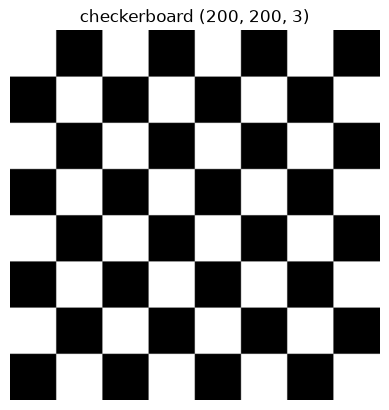

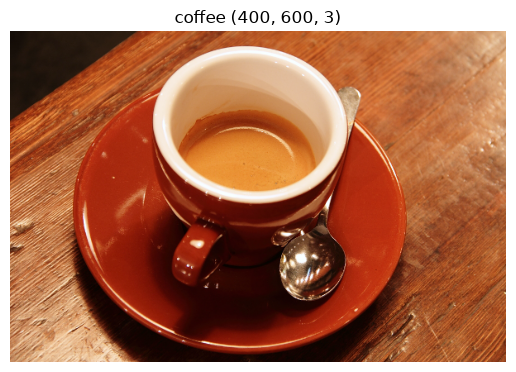

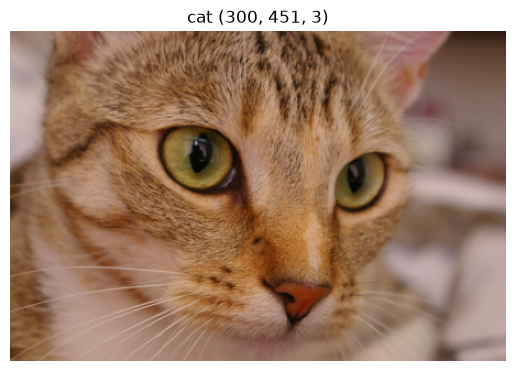

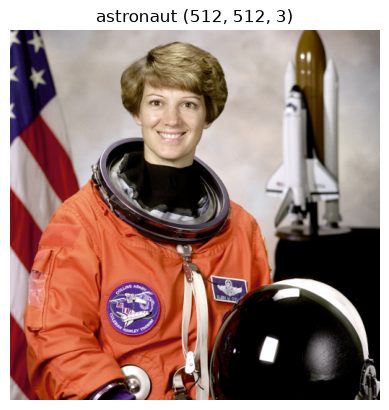

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

# checkerboard: obraz binarny 0/255 -> 3 kanały (RGB)
checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img, name in zip(imgs_color, image_names):
    plt.imshow(img)
    plt.title(f"{name} {img.shape}")   # kształt: (wysokość, szerokość, kanały)
    plt.axis('off')
    plt.show()

Zbieramy obrazy w słowniku (wygodny dostęp po nazwie) i definiujemy funkcję `show`, która rysuje kilka obrazów obok siebie. Wypisujemy też rozmiary i typ danych – dla wszystkich obrazów powinno być `uint8` i 3 kanały.

In [2]:
# słownik: nazwa -> obraz
images = dict(zip(image_names, imgs_color))


def show(imgs, titles, figsize=None):
    """Rysuje obrazy w jednym rzędzie, każdy z własnym tytułem."""
    fig, axes = plt.subplots(1, len(imgs), figsize=figsize or (4 * len(imgs), 4))
    for ax, im, t in zip(np.atleast_1d(axes), imgs, titles):
        ax.imshow(im)
        ax.set_title(t, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


for name, img in images.items():
    print(f"{name:13s} shape={img.shape}, dtype={img.dtype}, wartości {img.min()}..{img.max()}")

checkerboard  shape=(200, 200, 3), dtype=uint8, wartości 0..255
coffee        shape=(400, 600, 3), dtype=uint8, wartości 0..255
cat           shape=(300, 451, 3), dtype=uint8, wartości 0..231
astronaut     shape=(512, 512, 3), dtype=uint8, wartości 0..255


## 3. Implementacja

Algorytm składa się z pięciu funkcji. Kolejne komórki opisują je po kolei, a na końcu jest mini-demo na małych danych oraz test poprawności.

### 3.1 Importy, stała i strumienie zależne od klucza
`key_streams(n, k, key)` zwraca dwie rzeczy wyznaczone **deterministycznie** z klucza:
- `perm` – losową permutację liczb `0..n-1` (do mieszania porcji),
- `mask` – losowe liczby `0..2^k-1` (po jednej na porcję), służące jako maska XOR.

Ponieważ generator jest deterministyczny, ten sam `key` daje zawsze te same `perm` i `mask`. Dzięki temu nadawca i odbiorca mogą niezależnie wygenerować identyczne strumienie. Stała `HEADER_BITS = 32` to długość nagłówka (dwie liczby 16-bitowe: wysokość i szerokość sekretu).

In [3]:
from skimage.transform import resize
from skimage.metrics import peak_signal_noise_ratio as psnr

HEADER_BITS = 32   # nagłówek: wysokość i szerokość sekretu (2 x uint16 = 32 bity)


def key_streams(n, k, key):
    """Permutacja n porcji i maska XOR (k bitów na porcję) wyznaczone z klucza."""
    rng = np.random.default_rng(key)                          # generator inicjowany kluczem
    perm = rng.permutation(n)                                 # losowa kolejność indeksów 0..n-1
    mask = rng.integers(0, 2 ** k, size=n, dtype=np.uint8)    # losowe porcje k-bitowe
    return perm, mask

### 3.2 Dopasowanie rozmiaru sekretu do pojemności
Pojemność nośnika w bitach to `H·W·3·k`, z czego 32 bity zajmuje nagłówek. Jeden piksel sekretu zajmuje `3·8 = 24` bity. Maksymalna liczba pikseli sekretu to więc `pojemność / 24`.

Jeśli sekret ma za dużo pikseli, zmniejszamy oba wymiary tym samym współczynnikiem `scale = sqrt(pojemność / (24·sh·sw))` (pierwiastek, bo skalujemy wysokość i szerokość jednocześnie). Dzięki temu **proporcje obrazu są zachowane**. Zaokrąglenie w dół gwarantuje, że wynik na pewno się zmieści. Jeśli sekret już się mieści, `scale >= 1` i zostaje bez zmian (nie powiększamy go).

Pomocnicza funkcja `upscale` powiększa odzyskany sekret do oryginalnych wymiarów, ale **tylko do wyświetlania i porównywania** – nie jest częścią algorytmu.

In [4]:
def fit_secret(secret, cover_shape, k):
    """Zmniejsza sekret (zachowując proporcje), aby zmieścił się w nośniku.
    Jeśli już się mieści, zwraca go bez zmian."""
    h, w, _ = cover_shape
    capacity_bits = h * w * 3 * k - HEADER_BITS      # pojemność nośnika po odjęciu nagłówka
    sh, sw = secret.shape[:2]
    scale = min(1.0, np.sqrt(capacity_bits / (24 * sh * sw)))   # 24 = 3 kanały * 8 bitów
    if scale == 1.0:
        return secret.copy()
    hs, ws = max(1, int(sh * scale)), max(1, int(sw * scale))   # zaokrąglenie w dół = na pewno się zmieści
    out = resize(secret, (hs, ws), anti_aliasing=True, preserve_range=True)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)


def upscale(img, shape_hw):
    """Powiększa obraz do (H, W) – wyłącznie na potrzeby wyświetlania i porównań."""
    out = resize(img, shape_hw, order=3, preserve_range=True)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

### 3.3 Osadzanie (`embed`)
Funkcja realizuje kroki 1–6 z opisu algorytmu:

1. **Dopasowanie** sekretu do pojemności (`fit_secret`).
2. **Nagłówek + dane:** wysokość i szerokość sekretu zapisujemy jako dwie liczby 16-bitowe (`>u2` = big-endian), doklejamy do nich wszystkie bajty sekretu i rozbijamy na pojedyncze bity (`np.unpackbits`).
3. **Porcje po `k` bitów:** liczba porcji `n` jest równa liczbie kanałów nośnika (`H·W·3`). Strumień uzupełniamy zerami do długości `n·k`, dzielimy na wiersze po `k` bitów i zamieniamy każdy wiersz na liczbę (np. bity `1,0` → `2`).
4. **Permutacja:** `scrambled[perm] = chunks` oznacza „porcja numer `i` ląduje na pozycji `perm[i]`".
5. **XOR** z maską.
6. **Zapis w nośniku:** zerujemy `k` najmłodszych bitów kanałów (`& keep`) i wstawiamy tam porcje (`| scrambled`). Przykładowo dla `k = 2`: `keep = 11111100`.

In [5]:
def embed(cover, secret, key, k=2):
    """Osadza obraz `secret` w obrazie `cover`. Zwraca stego-obraz (uint8, ten sam kształt co cover)."""
    assert cover.dtype == np.uint8 and cover.ndim == 3 and cover.shape[2] == 3
    assert 1 <= k <= 4, "k poza zakresem 1..4 (większe k zbyt mocno psuje nośnik)"

    # 1. dopasuj rozmiar sekretu do pojemności nośnika
    small = fit_secret(secret, cover.shape, k)
    hs, ws = small.shape[:2]

    # 2. strumień bitów: nagłówek (hs, ws jako 2 x uint16) + wszystkie bajty sekretu
    header = np.array([hs, ws], dtype=">u2").view(np.uint8)
    bits = np.unpackbits(np.concatenate([header, small.reshape(-1)]))

    # 3. pokrój na porcje po k bitów; liczba porcji n = liczba kanałów nośnika
    n = cover.size
    bits = np.pad(bits, (0, n * k - bits.size))                  # uzupełnij zerami do pełnej pojemności
    weights = 1 << np.arange(k - 1, -1, -1)                      # np. dla k=2: [2, 1]
    chunks = (bits.reshape(n, k) * weights).sum(axis=1).astype(np.uint8)   # k bitów -> liczba 0..2^k-1

    # 4. permutacja porcji + 5. XOR z maską (oba z klucza)
    perm, mask = key_streams(n, k, key)
    scrambled = np.empty_like(chunks)
    scrambled[perm] = chunks                                     # porcja i -> pozycja perm[i]
    scrambled ^= mask

    # 6. zapis: wyzeruj k najmłodszych bitów nośnika i wstaw tam porcje
    keep = np.uint8((0xFF << k) & 0xFF)                          # np. k=2 -> 11111100
    stego = (cover.reshape(-1) & keep) | scrambled
    return stego.reshape(cover.shape)

### 3.4 Wyodrębnianie (`extract`)
Wszystkie kroki odwracamy w odwrotnej kolejności. Odbiorca nie zna rozmiaru sekretu, więc **najpierw odczytuje nagłówek** (pierwsze 32 bity), a potem dokładnie tyle bitów danych, ile ten nagłówek zapowiada.

Jeżeli klucz jest zły, strumienie `perm` i `mask` się nie zgadzają, więc „nagłówek" to losowe liczby, które zwykle zapowiadają więcej danych, niż w ogóle mieści stego-obraz. Funkcja to wykrywa i zgłasza błąd `ValueError` zamiast zwracać śmieci.

In [6]:
def extract(stego, key, k=2):
    """Odzyskuje obraz tajny ze stego-obrazu (wymaga tego samego key i k).
    Zwraca obraz uint8 o kształcie (hs, ws, 3), czyli w rozmiarze, w którym został ukryty."""
    n = stego.size
    perm, mask = key_streams(n, k, key)                          # te same strumienie co przy osadzaniu

    # odczyt k LSB z każdego kanału -> XOR z maską -> permutacja odwrotna (chunks[i] = zapisane[perm[i]])
    chunks = ((stego.reshape(-1) & np.uint8(2 ** k - 1)) ^ mask)[perm]

    # porcje (liczby) -> z powrotem pojedyncze bity
    shifts = np.arange(k - 1, -1, -1)
    bits = ((chunks[:, None] >> shifts) & 1).astype(np.uint8).reshape(-1)

    # nagłówek: 32 bity -> 4 bajty -> dwie liczby 16-bitowe (wysokość, szerokość)
    hs, ws = (int(v) for v in np.packbits(bits[:HEADER_BITS]).view(">u2"))
    need = HEADER_BITS + hs * ws * 24                            # tyle bitów powinien zajmować cały sekret
    if hs == 0 or ws == 0 or need > bits.size:
        raise ValueError("Nie znaleziono ukrytego obrazu (zły klucz lub k).")

    # dane: bity -> bajty -> obraz (hs, ws, 3)
    return np.packbits(bits[HEADER_BITS:need]).reshape(hs, ws, 3)

### 3.5 Mini-demo: co dzieje się z danymi krok po kroku
Zanim użyjemy algorytmu na obrazach, zobaczmy jego elementy na maleńkich danych.

**(a) Nadpisanie najmłodszych bitów jednego kanału** – ten sam przykład, co we wprowadzeniu.

**(b) Permutacja i XOR dla 8 porcji** – po zamieszaniu i wybieleniu porcje nie przypominają oryginału, ale znając klucz, odzyskujemy je dokładnie.

In [7]:
# (a) nadpisanie k najmłodszych bitów jednego kanału
k_demo = 2
pixel, chunk = 200, 2
keep = (0xFF << k_demo) & 0xFF
new_pixel = (pixel & keep) | chunk
print(f"kanał nośnika   : {pixel:3d} = {pixel:08b}")
print(f"porcja do ukrycia: {chunk:3d} = {chunk:08b}")
print(f"po osadzeniu    : {new_pixel:3d} = {new_pixel:08b}   (zmiana o {abs(new_pixel - pixel)})")

# (b) permutacja + XOR na 8 porcjach 2-bitowych
chunks_demo = np.array([3, 0, 2, 1, 1, 3, 0, 2], dtype=np.uint8)
perm_d, mask_d = key_streams(8, k_demo, key=7)

scrambled_d = np.empty_like(chunks_demo)
scrambled_d[perm_d] = chunks_demo        # permutacja
after_xor = scrambled_d ^ mask_d         # XOR

print("\nporcje oryginalne :", chunks_demo)
print("permutacja (perm) :", perm_d)
print("maska XOR         :", mask_d)
print("po permutacji     :", scrambled_d)
print("po XOR (zapisane) :", after_xor)

# odwrotnie: XOR tą samą maską, potem permutacja odwrotna
restored = (after_xor ^ mask_d)[perm_d]
print("odzyskane         :", restored, "-> zgodne z oryginałem:", np.array_equal(restored, chunks_demo))

kanał nośnika   : 200 = 11001000
porcja do ukrycia:   2 = 00000010
po osadzeniu    : 202 = 11001010   (zmiana o 2)

porcje oryginalne : [3 0 2 1 1 3 0 2]
permutacja (perm) : [0 6 7 2 4 5 1 3]
maska XOR         : [1 1 0 0 2 2 3 1]
po permutacji     : [3 0 1 2 1 3 0 2]
po XOR (zapisane) : [2 1 1 2 3 1 3 3]
odzyskane         : [3 0 2 1 1 3 0 2] -> zgodne z oryginałem: True


### 3.6 Test poprawności
Sprawdzamy trzy własności:
1. **Niewidoczność:** żaden kanał nośnika nie zmienił się o więcej niż `2^k − 1`.
2. **Poprawność:** z poprawnym kluczem odzyskujemy ukryty obraz **dokładnie** (co do bitu).
3. **Tajność:** ze złym kluczem nie da się odczytać obrazu.

In [8]:
cover, secret = images["coffee"], images["cat"]
k, key = 2, 2026

stego = embed(cover, secret, key, k)
rec = extract(stego, key, k)

# 1. maksymalna różnica między nośnikiem a stego-obrazem (rzutujemy na int, by uniknąć przepełnienia uint8)
print("max |stego - cover| :", np.abs(stego.astype(int) - cover.astype(int)).max(), f"(limit: {2 ** k - 1})")

# 2. odzysk ma być identyczny z sekretem zmniejszonym do tego, co się zmieściło
print("odzysk == ukryty obraz (bit w bit):", np.array_equal(rec, fit_secret(secret, cover.shape, k)))

# 3. zły klucz
try:
    extract(stego, key + 1, k)
    print("zły klucz: brak błędu (nagłówek przypadkiem wyglądał poprawnie)")
except ValueError as e:
    print("zły klucz ->", e)

max |stego - cover| : 3 (limit: 3)
odzysk == ukryty obraz (bit w bit): True
zły klucz -> Nie znaleziono ukrytego obrazu (zły klucz lub k).


## 4. Użycie

### 4.1 Przykład podstawowy
Nośnik: `coffee`, obraz tajny: `astronaut`, klucz `2026`, `k = 2`.

Obraz tajny jest przy osadzaniu zmniejszany, więc odzyskany obraz ma mniejszy rozmiar niż oryginał. Aby porównać go z oryginałem, powiększamy go funkcją `upscale` (tylko do wyświetlania).

Dwie miary jakości to **PSNR** (*peak signal-to-noise ratio*, w decybelach; im wyższy, tym obrazy są do siebie podobniejsze):
- `PSNR(cover, stego)` – jak bardzo stego-obraz różni się od nośnika. Wartości powyżej ok. 40 dB oznaczają zmiany praktycznie niewidoczne.
- `PSNR(sekret, odzysk powiększony)` – jak bardzo odzyskany sekret różni się od oryginału. Różnica wynika **wyłącznie** ze zmniejszenia rozdzielczości, bo sam odzysk jest bezstratny.

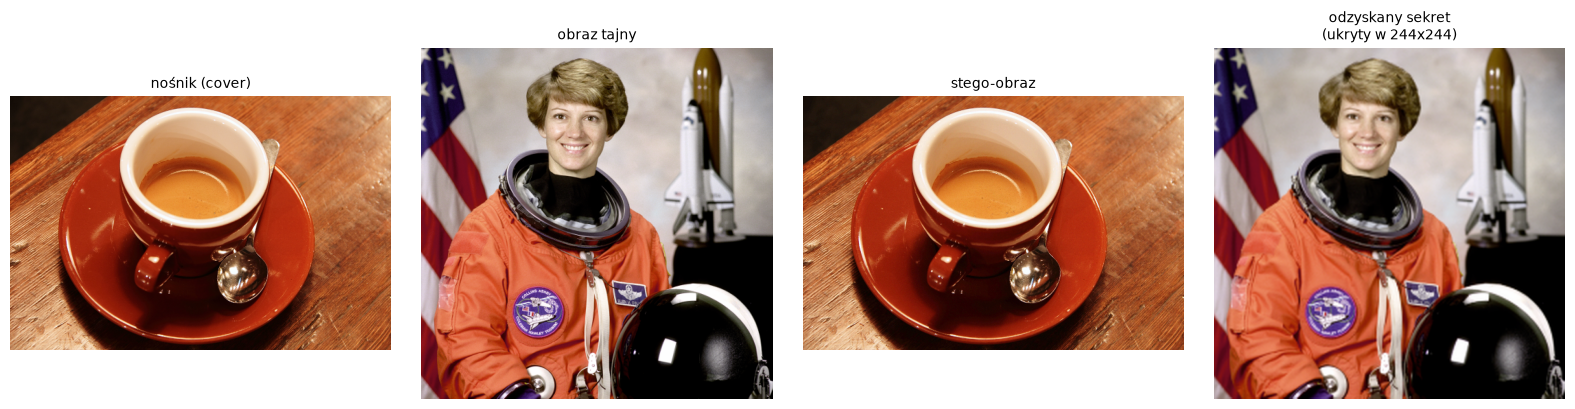

Rozmiar ukrytego sekretu: (244, 244) (oryginał: (512, 512))
PSNR(cover, stego)               = 44.14 dB   (niewidoczność)
PSNR(sekret, odzysk powiększony) = 29.93 dB


In [9]:
cover, secret = images["coffee"], images["astronaut"]
k, key = 2, 2026

stego = embed(cover, secret, key, k)             # ukrywanie
recovered = extract(stego, key, k)               # odzyskiwanie (w rozmiarze, w którym ukryto)
recovered_big = upscale(recovered, secret.shape[:2])   # tylko do porównania z oryginałem

show([cover, secret, stego, recovered_big],
     ["nośnik (cover)", "obraz tajny", "stego-obraz",
      f"odzyskany sekret\n(ukryty w {recovered.shape[1]}x{recovered.shape[0]})"])

print(f"Rozmiar ukrytego sekretu: {recovered.shape[:2]} (oryginał: {secret.shape[:2]})")
print(f"PSNR(cover, stego)               = {psnr(cover, stego):.2f} dB   (niewidoczność)")
print(f"PSNR(sekret, odzysk powiększony) = {psnr(secret, recovered_big):.2f} dB")

### 4.2 Zły klucz
Odbiorca, który nie zna klucza, nie jest w stanie nawet odczytać nagłówka z rozmiarem sekretu – zamiast obrazu dostaje błąd. Sprawdzamy dwa „bliskie" klucze: nawet różnica o 1 daje zupełnie inną permutację i maskę.

In [10]:
for wrong_key in [1234, 2027]:
    try:
        extract(stego, wrong_key, k)
        print(f"klucz {wrong_key}: odczytano coś (byłby to szum)")
    except ValueError as e:
        print(f"klucz {wrong_key}: {e}")

klucz 1234: Nie znaleziono ukrytego obrazu (zły klucz lub k).
klucz 2027: Nie znaleziono ukrytego obrazu (zły klucz lub k).


### 4.3 Gdzie i jak bardzo zmienił się nośnik?
Trzy obrazy:
- **LSB nośnika** i **LSB stego-obrazu** – płaszczyzny najmłodszych bitów (rozciągnięte do zakresu 0–255 dla czytelności). Obie powinny wyglądać jak szum. Dzięki permutacji i XOR-owi w stego-obrazie **nie widać żadnego zarysu ukrytego obrazu**.
- **Różnica |stego − cover|** (też rozciągnięta) – pokazuje, jak niewielkie są zmiany; nie przekraczają `2^k − 1`.

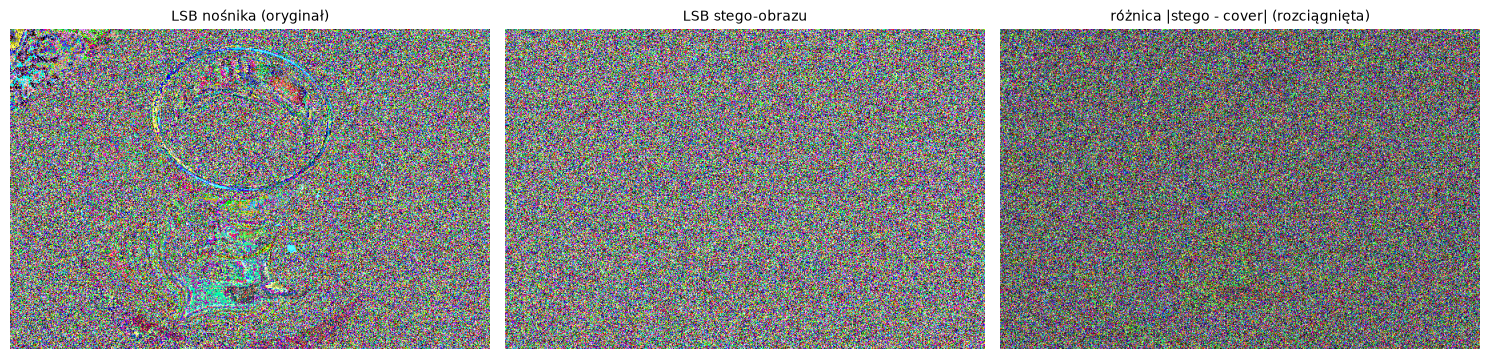

In [11]:
scale = 255 // (2 ** k - 1)                                    # rozciągnięcie 0..2^k-1 do 0..255 (tylko do wyświetlania)
lsb_mask = np.uint8(2 ** k - 1)

plane_cover = (cover & lsb_mask) * scale                       # k najmłodszych bitów nośnika
plane_stego = (stego & lsb_mask) * scale                       # k najmłodszych bitów stego-obrazu
diff = np.abs(stego.astype(int) - cover.astype(int)) * scale   # wielkość zmiany każdego kanału

show([plane_cover, plane_stego, diff.astype(np.uint8)],
     ["LSB nośnika (oryginał)", "LSB stego-obrazu", "różnica |stego - cover| (rozciągnięta)"],
     figsize=(15, 4.5))

### 4.4 Kompromis: liczba bitów `k`
`k` steruje kompromisem:
- **większe `k`** → większa pojemność, czyli sekret ukryty w wyższej rozdzielczości (ostrzejszy odzysk), ale bardziej zniekształcony nośnik (niższy PSNR nośnika),
- **mniejsze `k`** → nośnik prawie nietknięty, ale sekret zmniejszony mocniej.

Górny rząd to stego-obrazy, dolny to odzyskane sekrety (powiększone do oryginalnych wymiarów).

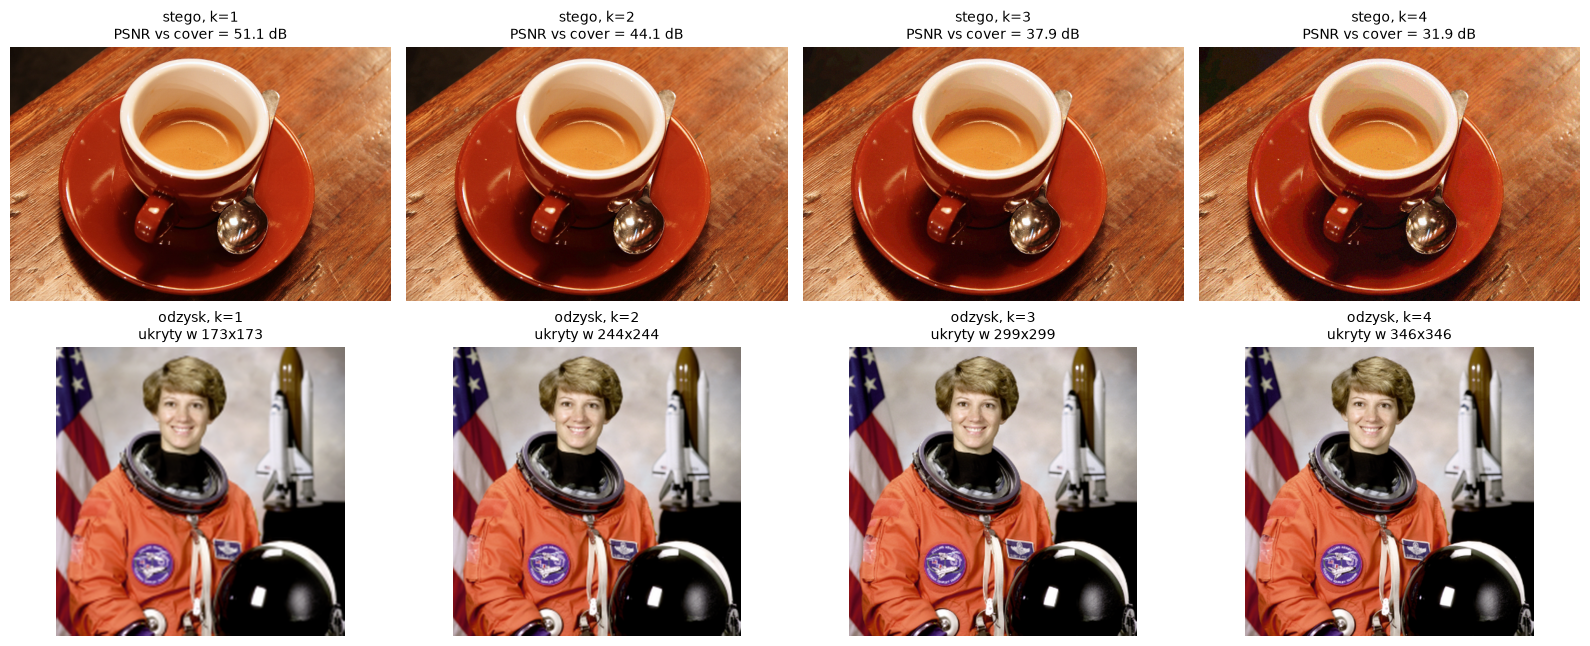

In [12]:
ks = [1, 2, 3, 4]
fig, axes = plt.subplots(2, len(ks), figsize=(4 * len(ks), 6.5))
for j, kk in enumerate(ks):
    st = embed(cover, secret, key, kk)                         # ukrywanie z kk bitami
    rc = extract(st, key, kk)                                  # odzysk
    axes[0, j].imshow(st)
    axes[0, j].set_title(f"stego, k={kk}\nPSNR vs cover = {psnr(cover, st):.1f} dB", fontsize=10)
    axes[1, j].imshow(upscale(rc, secret.shape[:2]))
    axes[1, j].set_title(f"odzysk, k={kk}\nukryty w {rc.shape[1]}x{rc.shape[0]}", fontsize=10)
    axes[0, j].axis('off'); axes[1, j].axis('off')
plt.tight_layout()
plt.show()

### 4.5 Wszystkie pary nośnik / obraz tajny (`k = 2`)
Tabela dla każdej pary różnych obrazów:
- `PSNR cover-stego` – niewidoczność zmian w nośniku,
- `rozmiar ukrytego sekretu` – w jakiej rozdzielczości (szerokość×wysokość) udało się go ukryć (zależy od rozmiaru nośnika),
- `odzysk bezstratny` – czy odzyskany obraz jest bit w bit taki sam jak ukryty (powinno być `True` zawsze).

In [13]:
import pandas as pd

rows = []
for c_name, c_img in images.items():           # c = nośnik (cover)
    for s_name, s_img in images.items():       # s = sekret (secret)
        if c_name == s_name:
            continue
        st = embed(c_img, s_img, key, k=2)
        rc = extract(st, key, k=2)
        rows.append({
            "nośnik": c_name,
            "sekret": s_name,
            "PSNR cover-stego [dB]": round(psnr(c_img, st), 2),
            "rozmiar ukrytego sekretu": f"{rc.shape[1]}x{rc.shape[0]}",
            "odzysk bezstratny": np.array_equal(rc, fit_secret(s_img, c_img.shape, 2)),
        })

pd.DataFrame(rows)

,nośnik,sekret,PSNR cover-stego [dB],rozmiar ukrytego sekretu,odzysk bezstratny
0,checkerboard,coffee,42.68,122x81,True
1,checkerboard,cat,42.68,122x81,True
2,checkerboard,astronaut,42.69,99x99,True
3,coffee,checkerboard,44.16,200x200,True
4,coffee,cat,44.15,300x199,True
5,coffee,astronaut,44.14,244x244,True
6,cat,checkerboard,44.15,183x183,True
7,cat,coffee,44.15,225x150,True
8,cat,astronaut,44.15,183x183,True
9,astronaut,checkerboard,44.01,200x200,True


### 4.6 Wnioski
- Sekret jest odzyskiwany **bezstratnie** w rozmiarze, w którym został ukryty, z zachowaniem proporcji. Różnica względem oryginału wynika wyłącznie ze zmniejszenia rozdzielczości.
- Zniekształcenie nośnika zależy tylko od `k`: każdy kanał zmienia się maksymalnie o `2^k − 1`.
- Permutacja i XOR sprawiają, że najmłodsze bity nie zdradzają struktury ukrytego obrazu, a bez klucza nie da się nawet odczytać nagłówka.
- Pojemność ogranicza rozmiar nośnika: duży nośnik (`coffee`, `astronaut`) mieści sekret w dobrej rozdzielczości, mały (`checkerboard`) tylko miniaturę.
- `k = 2` to rozsądny kompromis; `k = 3–4` warto wybrać, gdy ważniejsza jest rozdzielczość sekretu niż doskonała niewidoczność zmian.
- Możliwe usprawnienia: bezstratna kompresja sekretu przed osadzeniem (więcej miejsca na rozdzielczość), osadzanie adaptacyjne (więcej bitów w obszarach z teksturą), kody korekcji błędów, szyfrowanie sekretu kryptograficznie bezpiecznym algorytmem.